In [65]:
DOWNLOAD_PROJECT = True
if DOWNLOAD_PROJECT:
    import zipfile
    archive = PROJECT.parent / 'NYC_Colab_Project_Export.zip'
    with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
        for path in PROJECT.rglob('*'):
            if path.is_file() and not any(part in {'__pycache__', '.pytest_cache'} for part in path.parts):
                z.write(path, path.relative_to(PROJECT.parent))
    try:
        from google.colab import files
        files.download(str(archive))
    except ImportError:
        print('Export saved:', archive)
else:
    print('Optional: set DOWNLOAD_PROJECT = True to export all project files.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

GIU_NYC_Development_Mobility

---


---




*   Member 1 Eyad Elsafty 16003613
*   Member 2
*   Member 3
*   Member 4



1. Install dependencies and create the project folder

In [34]:
%pip install -q "pandas>=2.2,<3" "numpy>=2,<3" "requests>=2.32,<3" "matplotlib>=3.9,<4" "seaborn>=0.13,<1" "plotly>=6,<8" "dash>=3,<5" "gunicorn>=23,<27" "pytest>=8,<10"

In [35]:
from pathlib import Path
import os, sys
BASE = Path('/content') if Path('/content').exists() else Path.cwd()
PROJECT = BASE / 'nyc_development_mobility_colab'
PROJECT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
for folder in ['data/raw', 'data/processed', 'reports', 'assets']:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)
print('Project folder:', PROJECT)


Project folder: /content/nyc_development_mobility_colab


2. Project source files
Run each cell once. You can expand and edit the code directly here. The modules separate extraction, cleaning, EDA, charts and the web application.

pipeline.py

In [36]:
%%writefile pipeline.py
"""Reproducible NYC extraction, cleaning and aggregate integration."""
from pathlib import Path
import argparse, hashlib, json, os, re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

ROOT = Path(__file__).resolve().parent
BOROUGHS = ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']
START, END = '2022-01-01', '2025-01-01'  # closed calendar years; end exclusive
SOURCES = {
 'housing': dict(id='rbx6-tga4', date='issued_date', columns=['job_filing_number','work_permit','sequence_number','borough','issued_date','approved_date','work_type','permit_status','zip_code','bin','estimated_job_costs','latitude','longitude','filing_reason']),
 'transport': dict(id='ez4e-fazm', date='occurred_on', columns=['busbreakdown_id','occurred_on','created_on','last_updated_on','boro','reason','run_type','how_long_delayed','number_of_students_on_the_bus','breakdown_or_running_late','school_year','route_number'])
}

def session():
    s = requests.Session()
    s.mount('https://', HTTPAdapter(max_retries=Retry(total=4, backoff_factor=1, status_forcelist=[429,500,502,503,504])))
    if os.getenv('SOCRATA_APP_TOKEN'): s.headers['X-App-Token'] = os.environ['SOCRATA_APP_TOKEN']
    return s

def extract(name, start=START, end=END):
    spec = SOURCES[name]; sid = spec['id']; s = session()
    def get(url, params=None):
        r = s.get(url, params=params, timeout=120); r.raise_for_status(); return r.json()
    api = f'https://data.cityofnewyork.us/resource/{sid}.json'
    meta = get(f'https://data.cityofnewyork.us/api/views/{sid}.json')
    fields = [c['fieldName'] for c in meta['columns'] if not c['fieldName'].startswith(':')]
    missing = set(spec['columns']) - set(fields)
    if len(fields) < 9 or missing: raise ValueError(f'Schema changed: {missing}; columns={len(fields)}')
    where = f"{spec['date']} >= '{start}T00:00:00' AND {spec['date']} < '{end}T00:00:00'"
    count = lambda clause: int(get(api, {'$select':'count(*) as n', **({'$where':clause} if clause else {})})[0]['n'])
    total, expected = count(None), count(where)
    pages=[]; offset=0
    while True:
        records = get(api, {'$select':','.join(spec['columns']), '$where':where, '$order':':id', '$limit':50000, '$offset':offset})
        if not records: break
        pages.append(pd.DataFrame(records)); offset += len(records)
        print(f'{name}: {offset:,}/{expected:,}', flush=True)
        if len(records)<50000: break
    if offset != expected or count(where) != expected:
        raise RuntimeError('Source count changed or extraction truncated. Retry extraction; no output accepted.')
    after=get(f'https://data.cityofnewyork.us/api/views/{sid}.json')
    if meta.get('rowsUpdatedAt') != after.get('rowsUpdatedAt'):
        raise RuntimeError('Source updated during pagination. Retry on a stable snapshot.')
    if not pages: raise ValueError('No rows in requested window')
    df=pd.concat(pages,ignore_index=True).reindex(columns=spec['columns'])
    raw=ROOT/'data/raw';raw.mkdir(parents=True,exist_ok=True)
    path=raw/f'{name}.csv.gz'; df.to_csv(path,index=False,compression='gzip')
    manifest=dict(name=meta['name'], dataset_id=sid, full_source_rows=total, source_columns=len(fields), extracted_rows=len(df), extracted_columns=len(df.columns), start=start,end_exclusive=end,retrieved_utc=datetime.now(timezone.utc).isoformat(), rows_updated_at=meta.get('rowsUpdatedAt'),where=where,fields=spec['columns'],sha256=hashlib.sha256(path.read_bytes()).hexdigest(),api=api,download=f'https://data.cityofnewyork.us/api/views/{sid}/rows.csv?accessType=DOWNLOAD')
    (raw/f'{name}_manifest.json').write_text(json.dumps(manifest,indent=2))
    (raw/f'{name}_schema.json').write_text(json.dumps(meta,indent=2))
    return df,manifest

def clean(df, name, start=START, end=END):
    d=df.copy(); audit={'input_rows':len(d)}
    for c in d.select_dtypes(include=['object','string']).columns:
        d[c]=d[c].astype('string').str.strip().replace('',pd.NA)
    d=d.drop_duplicates();audit['exact_duplicates_removed']=len(df)-len(d)
    date=SOURCES[name]['date'];d['date']=pd.to_datetime(d[date],errors='coerce',format='mixed')
    b='borough' if name=='housing' else 'boro'
    aliases={'1':'MANHATTAN','2':'BRONX','3':'BROOKLYN','4':'QUEENS','5':'STATEN ISLAND','RICHMOND':'STATEN ISLAND','NEW YORK':'MANHATTAN','KINGS':'BROOKLYN','THE BRONX':'BRONX'}
    d['borough']=d[b].str.upper().replace(aliases)
    valid=d.borough.isin(BOROUGHS)&d.date.ge(start)&d.date.lt(end)
    audit['invalid_geography_or_date_removed']=int((~valid).sum());d=d.loc[valid].copy()
    if name=='transport':
        audit['missing_identifier_removed']=int(d.busbreakdown_id.isna().sum())
        d=d.dropna(subset=['busbreakdown_id'])
        d['update']=pd.to_datetime(d.last_updated_on,errors='coerce',format='mixed')
        n=len(d);d=d.sort_values(['update','created_on'],na_position='first',kind='stable').drop_duplicates('busbreakdown_id',keep='last')
        audit['duplicate_ids_removed']=n-len(d)
        d['category']=d.reason.fillna('UNKNOWN').str.upper()
        d['students']=pd.to_numeric(d.number_of_students_on_the_bus,errors='coerce')
        bad=(d.students<0)|(d.students>100)|(d.students%1!=0)
        audit['students_invalid_or_missing']=int((bad|d.students.isna()).sum());d.loc[bad,'students']=np.nan
        d['delay_minutes']=d.how_long_delayed.map(parse_delay)
        audit['delay_unusable']=int(d.delay_minutes.isna().sum())
    else:
        # Grain: permit-work-type issuance record; preserve multi-work permits and renewals.
        keys=['job_filing_number','work_permit','sequence_number']
        audit['missing_identifier_removed']=int(d[keys].isna().any(axis=1).sum())
        d=d.dropna(subset=keys)
        invalid_id=~d.job_filing_number.str.match(r'^[BMQSX][0-9]+-',na=False)
        audit['placeholder_identifiers_removed']=int(invalid_id.sum())
        d=d.loc[~invalid_id].copy()
        d['category']=d.work_type.fillna('UNKNOWN').str.upper()
        keys += ['date','category']
        duplicated=d.duplicated(keys,keep=False)
        # Conflicting natural keys cannot be safely reconciled without version timestamps.
        audit['conflicting_key_rows_quarantined']=int(duplicated.sum())
        d=d.loc[~duplicated].copy()
        d['category']=d.work_type.fillna('UNKNOWN').str.upper()
        d['zip_code']=d.zip_code.str.extract(r'^(\d{5})(?:-\d{4})?$')[0]
        d['cost']=pd.to_numeric(d.estimated_job_costs.str.replace(r'[$,]','',regex=True),errors='coerce')
        audit['negative_costs']=int((d.cost<0).sum());d.loc[d.cost<0,'cost']=np.nan
        q1,q3=d.cost.quantile([.25,.75]);d['cost_iqr_outlier']=(d.cost<q1-1.5*(q3-q1))|(d.cost>q3+1.5*(q3-q1))
        audit['cost_iqr_outliers_retained']=int(d.cost_iqr_outlier.sum())
        for c,lo,hi in [('latitude',40.45,40.95),('longitude',-74.3,-73.65)]:
            d[c]=pd.to_numeric(d[c],errors='coerce');d.loc[~d[c].between(lo,hi),c]=np.nan
    d['month']=d.date.dt.to_period('M').dt.to_timestamp()
    audit['output_rows']=len(d)
    return d,audit

def parse_delay(value):
    """Parse only explicit minutes, hours or bounded numeric ranges; no guessed text."""
    if pd.isna(value): return np.nan
    t=str(value).strip().lower()
    m=re.fullmatch(r'(\d+(?:\.\d+)?)\s*(?:-\s*(\d+(?:\.\d+)?))?\s*(min(?:ute)?s?|hr?s?|hours?)?',t)
    if not m: return np.nan
    a=float(m[1]);b=float(m[2]) if m[2] else a
    if b<a:return np.nan
    v=(a+b)/2*(60 if m[3] and m[3].startswith(('h')) else 1)
    return v if 0<=v<=240 else np.nan

def aggregate(h,t):
    keys=['borough','month','category']
    ha=h.groupby(keys,dropna=False).size().rename('permits').reset_index()
    ta=t.groupby(keys,dropna=False).agg(incidents=('busbreakdown_id','size'),delay_sum=('delay_minutes','sum'),delay_n=('delay_minutes','count'),student_sum=('students','sum'),student_n=('students','count')).reset_index()
    return ha,ta

def integrate(ha,ta,hcategory='ALL',tcategory='ALL'):
    """Filter each domain BEFORE aggregation; category dimensions never cross-join."""
    keys=['borough','month']
    h=ha if hcategory=='ALL' else ha[ha.category==hcategory]
    t=ta if tcategory=='ALL' else ta[ta.category==tcategory]
    h=h.groupby(keys).permits.sum().reset_index()
    t=t.groupby(keys)[['incidents','delay_sum','delay_n','student_sum','student_n']].sum().reset_index()
    # Coverage uses unfiltered sources: missing domain-month remains unknown, never fabricated zero.
    coverage=ha[keys].drop_duplicates().merge(ta[keys].drop_duplicates(),on=keys,how='outer',indicator=True,validate='one_to_one')
    out=coverage.merge(h,on=keys,how='left',validate='one_to_one').merge(t,on=keys,how='left',validate='one_to_one')
    hseen=out._merge.isin(['left_only','both']);tseen=out._merge.isin(['right_only','both'])
    out.loc[hseen,'permits']=out.loc[hseen,'permits'].fillna(0)
    tc=['incidents','delay_sum','delay_n','student_sum','student_n']
    out.loc[tseen,tc]=out.loc[tseen,tc].fillna(0)
    out['mean_delay']=out.delay_sum/out.delay_n.replace(0,np.nan)
    out['mean_students']=out.student_sum/out.student_n.replace(0,np.nan)
    out['delay_coverage']=out.delay_n/out.incidents.replace(0,np.nan)
    out['year']=pd.to_datetime(out.month).dt.year
    return out.rename(columns={'_merge':'coverage'}).sort_values(keys).reset_index(drop=True)

def build(start=START,end=END,download=True):
    frames={};audits={};manifests={}
    for name in SOURCES:
        if download: raw,manifest=extract(name,start,end)
        else:
            raw=pd.read_csv(ROOT/f'data/raw/{name}.csv.gz',dtype='string')
            manifest=json.loads((ROOT/f'data/raw/{name}_manifest.json').read_text())
            if (manifest['start'],manifest['end_exclusive'])!=(start,end):raise ValueError('Cached window differs')
        frames[name],audits[name]=clean(raw,name,start,end);manifests[name]=manifest
    ha,ta=aggregate(frames['housing'],frames['transport']);panel=integrate(ha,ta)
    dest=ROOT/'data/processed';dest.mkdir(parents=True,exist_ok=True)
    for name,frame in [('housing_monthly',ha),('transport_monthly',ta),('integrated',panel)]:frame.to_csv(dest/f'{name}.csv',index=False)
    (dest/'provenance.json').write_text(json.dumps({'sources':manifests,'cleaning':audits},indent=2))
    print(json.dumps(audits,indent=2));return frames,ha,ta,panel

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--cached',action='store_true');args=p.parse_args();build(download=not args.cached)


Overwriting pipeline.py


eda.py

In [37]:
%%writefile eda.py
"""Raw-data diagnostics; EDA figures are separate from eight research figures."""
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pipeline import ROOT, SOURCES

def inspect(name,df):
    out=ROOT/'reports';out.mkdir(exist_ok=True)
    profile=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing_n':df.isna().sum(),'missing_pct':100*df.isna().mean(),'unique_n':df.nunique()})
    profile.to_csv(out/f'{name}_profile.csv')
    df.describe(include='all').to_csv(out/f'{name}_summary.csv')
    print(name,df.shape,'exact duplicates:',df.duplicated().sum())
    print(profile.to_string())
    fig,axs=plt.subplots(1,2,figsize=(14,5))
    profile.missing_pct.sort_values().plot.barh(ax=axs[0],title=f'{name}: missing values (%)')
    category='work_type' if name=='housing' else 'reason'
    counts=df[category].fillna('UNKNOWN').value_counts().head(10)
    sns.barplot(x=counts.values,y=counts.index,ax=axs[1],color='#147d69');axs[1].set_title(f'{name}: top categories');axs[1].set_xlabel('Records')
    fig.tight_layout();fig.savefig(out/f'{name}_eda.png',dpi=140);plt.show()
    dates=pd.to_datetime(df[SOURCES[name]['date']],format='mixed',errors='coerce')
    print('Invalid dates:',dates.isna().sum(),'date range:',dates.min(),dates.max())
    return profile

def numeric_eda(h,t):
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    sns.histplot(h.loc[h.cost>0,"cost"],ax=axs[0],log_scale=(True,False));axs[0].set_title('Valid positive job costs (log scale)')
    sns.histplot(t.delay_minutes.dropna(),ax=axs[1],bins=30);axs[1].set_title('Parsed delay estimates (minutes)')
    fig.tight_layout();fig.savefig(ROOT/'reports/clean_distributions.png',dpi=140);plt.show()
    print('Costs (not summed across permits):\n',h.cost.describe())
    print('Delay minutes:\n',t.delay_minutes.describe())


Overwriting eda.py


charts.py

In [38]:
%%writefile charts.py
"""Eight research questions shared by notebook and dashboard."""
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

QUESTIONS=[
 ('Member 1','Do borough-months with more permit activity also report more school-bus incidents?','Scatter: counts, coloured by borough; exposes scale confounding.'),
 ('Member 1','Do permit and incident trends move together within each borough relative to its first selected month?','Indexed time series: baseline 100, one panel per borough.'),
 ('Member 2','Which seasons show unusually high incident reporting relative to development activity?','Heatmap: incident seasonal index minus permit seasonal index.'),
 ('Member 2','Are year-over-year changes in permits associated with changes in incident reports?','Scatter: same-month annual percentage changes, avoiding adjacent-season comparisons.'),
 ('Member 3','Is permit activity associated with incident reporting one to three months later?','Heatmap: within-borough Spearman correlations at calendar-aligned lags, including lag zero.'),
 ('Member 3','Are reported delays longer in high-permit months than low-permit months within a borough?','Box plot of monthly mean delay, split at each borough’s median permit count.'),
 ('Member 4','Which boroughs account for a larger share of reported incidents than of permit activity?','Grouped share bars: descriptive concentration, not an exposure-adjusted risk.'),
 ('Member 4','Does the relationship persist after removing borough and shared calendar-month effects?','Residual scatter: additive borough and date fixed effects for both count variables.')]

def blank(message):
    f=go.Figure();f.add_annotation(text=message,x=.5,y=.5,xref='paper',yref='paper',showarrow=False);return f

def figures(panel):
    d=panel[panel.coverage.astype(str)=='both'].copy().sort_values(['borough','month'])
    d['month']=pd.to_datetime(d.month)
    if d.empty:return [blank('No matched borough-months for these filters.') for _ in QUESTIONS]
    fs=[]
    fs.append(px.scatter(d,x='permits',y='incidents',color='borough',hover_data=['month']))
    z=d.copy()
    for c in ['permits','incidents']:
        first=z.groupby('borough')[c].transform('first').replace(0,np.nan)
        z[c]=100*z[c]/first
    z=z.melt(id_vars=['borough','month'],value_vars=['permits','incidents'],var_name='metric',value_name='index')
    fs.append(px.line(z,x='month',y='index',color='metric',facet_col='borough',facet_col_wrap=2,markers=True))
    z=d.assign(month_number=d.month.dt.month).groupby(['borough','month_number'])[['permits','incidents']].mean().reset_index()
    for c in ['permits','incidents']:z[c]=100*z[c]/z.groupby('borough')[c].transform('mean').replace(0,np.nan)
    z['gap']=z.incidents-z.permits
    fs.append(px.imshow(z.pivot(index='borough',columns='month_number',values='gap'),color_continuous_scale='RdBu_r',color_continuous_midpoint=0,labels={'color':'Index-point gap','x':'Month of year'}))
    old=d[['borough','month','permits','incidents']].copy();old['month']+=pd.DateOffset(years=1)
    y=d.merge(old,on=['borough','month'],suffixes=('','_prior'),validate='one_to_one')
    for c in ['permits','incidents']:y[c+'_yoy']=100*(y[c]/y[c+'_prior'].replace(0,np.nan)-1)
    y=y.dropna(subset=['permits_yoy','incidents_yoy'])
    fs.append(px.scatter(y,x='permits_yoy',y='incidents_yoy',color='borough',hover_data=['month']) if len(y) else blank('Select at least two overlapping calendar years; zero baselines are excluded.'))
    rows=[]
    for borough,g in d.groupby('borough'):
        for lag in range(4):
            x=g[['month','permits']].copy();x['month']+=pd.DateOffset(months=lag)
            a=x.merge(g[['month','incidents']],on='month')
            r=a.permits.rank().corr(a.incidents.rank()) if len(a)>=12 and a.permits.nunique()>1 and a.incidents.nunique()>1 else np.nan
            rows.append({'borough':borough,'lag':lag,'rho':r,'pairs':len(a)})
    z=pd.DataFrame(rows)
    f=px.imshow(z.pivot(index='borough',columns='lag',values='rho'),zmin=-1,zmax=1,color_continuous_scale='RdBu_r',labels={'x':'Months after permits','color':'Spearman rho'})
    fs.append(f)
    z=d[d.delay_n>=10].copy();z['activity']=np.where(z.permits>z.groupby('borough').permits.transform('median'),'High permits','Low/equal permits')
    fs.append(px.box(z,x='borough',y='mean_delay',color='activity',points='all',hover_data=['month','delay_n','delay_coverage']) if len(z) else blank('At least 10 usable delay estimates per borough-month are required.'))
    z=d.groupby('borough')[['permits','incidents']].sum()
    z=100*z/z.sum().replace(0,np.nan)
    fs.append(px.bar(z.reset_index().melt(id_vars='borough',var_name='metric',value_name='share_pct'),x='borough',y='share_pct',color='metric',barmode='group'))
    x=pd.get_dummies(d[['borough','month']].astype(str),drop_first=True,dtype=float)
    x=np.column_stack([np.ones(len(d)),x.to_numpy()])
    if len(d)-np.linalg.matrix_rank(x)>=5:
        z=d.copy()
        for c in ['permits','incidents']:
            v=z[c].to_numpy(float);z[c+'_residual']=v-x@np.linalg.lstsq(x,v,rcond=None)[0]
        fs.append(px.scatter(z,x='permits_residual',y='incidents_residual',color='borough',hover_data=['month']))
    else:fs.append(blank('Select more boroughs/months: fewer than 5 residual degrees of freedom.'))
    for i,f in enumerate(fs):
        f.update_layout(title=f'Q{i+1} · {QUESTIONS[i][0]}',template='plotly_white',margin=dict(l=50,r=30,t=60,b=50),height=480)
    return fs

def story(panel):
    d=panel[panel.coverage.astype(str)=='both']
    if d.empty:return 'No paired observations. Broaden the filters; missing coverage is not zero activity.'
    rho=d.permits.rank().corr(d.incidents.rank()) if d.permits.nunique()>1 and d.incidents.nunique()>1 else np.nan
    r=f'{rho:.2f}' if pd.notna(rho) else 'undefined (constant counts)'
    return (f'For the applied filters, {len(d)} matched borough-months contain {d.permits.sum():,.0f} permit records and '
            f'{d.incidents.sum():,.0f} reported school-bus incidents. The pooled Spearman correlation is {r}. '
            'This is a descriptive association, not evidence that construction causes delays. Borough size, school schedules, '
            'reporting practices and traffic exposure can explain co-movement. Permits include non-residential work and do not '
            'measure completed homes. Incident reports exclude on-time journeys; rates of failure cannot be calculated. '
            'Use these patterns to nominate boroughs and periods for joint DOB/DOE review and route-level follow-up, not to rank safety or assign blame.')


Overwriting charts.py


app.py

In [39]:
%%writefile app.py
"""Run python app.py after python pipeline.py. No downloads occur in web requests."""
import json,re
import pandas as pd
from dash import Dash,Input,Output,State,dcc,html,no_update
from pipeline import ROOT,BOROUGHS,integrate
from charts import QUESTIONS,figures,story,blank

DATA=ROOT/'data/processed'
ready=all((DATA/f'{n}.csv').exists() for n in ['housing_monthly','transport_monthly'])
if ready:
    H=pd.read_csv(DATA/'housing_monthly.csv',parse_dates=['month'])
    T=pd.read_csv(DATA/'transport_monthly.csv',parse_dates=['month'])
else:
    H=pd.DataFrame(columns=['borough','month','category','permits'])
    T=pd.DataFrame(columns=['borough','month','category','incidents','delay_sum','delay_n','student_sum','student_n'])
years=sorted(set(H.month.dt.year)|set(T.month.dt.year)) if ready else [2022,2023,2024]
hcats=['ALL']+sorted(H.category.unique().tolist());tcats=['ALL']+sorted(T.category.unique().tolist())
app=Dash(__name__);server=app.server
app.title='Building NYC · Moving Students'

def dropdown(id,label,options,value,multi=False):
    return html.Div([html.Label(label,htmlFor=id),dcc.Dropdown(options,value,id=id,multi=multi,clearable=False)])

app.layout=html.Main([
 html.Header([html.P('GIU · DATA ENGINEERING & VISUALIZATION · WINTER 2026',className='eyebrow'),html.H1('Building NYC. Moving students.'),html.P('Explore development activity and school-bus disruption across five boroughs, 2022–2024.')]),
 html.Section([html.Label('Search borough, year and category; press Enter or Apply Search'),html.Div([dcc.Input(id='search',placeholder='Brooklyn 2022 heavy traffic',debounce=True),html.Button('Apply Search',id='apply')],className='search'),html.Div(id='search-status'),
 html.Div([dropdown('borough','Borough',BOROUGHS,BOROUGHS,True),dropdown('year','Calendar year',years,years,True),dropdown('housing','Permit work type',hcats,'ALL'),dropdown('transport','Incident reason',tcats,'ALL')],className='filters'),
 html.Button('Generate Report',id='generate',n_clicks=0,className='primary'),html.P('Filters are staged. Generate Report refreshes all eight charts and the story.')],className='card'),
 html.Section([html.H2('Story'),html.P('Question: Do changes in development activity coincide with school-bus disruption?'),html.Div(id='story'),html.P(id='coverage')],className='card'),
 dcc.Loading(html.Div([html.Article([html.H2(f'Q{i+1} · {q[0]}'),html.P(q[1]),html.Small(q[2]),dcc.Graph(id=f'chart-{i}',figure=blank('Click Generate Report'))],className='card') for i,q in enumerate(QUESTIONS)],className='charts')),
 html.Footer([html.A('DOB NOW source',href='https://data.cityofnewyork.us/d/rbx6-tga4'), ' · ',html.A('School-bus source',href='https://data.cityofnewyork.us/d/ez4e-fazm'),html.P('Borough-month association · no causal interpretation · reported incidents, not all journeys')])
])

@app.callback(Output('borough','value'),Output('year','value'),Output('housing','value'),Output('transport','value'),Output('search-status','children'),Input('apply','n_clicks'),Input('search','n_submit'),State('search','value'),prevent_initial_call=True)
def search(_click,_enter,query):
    q=(query or '').upper().strip()
    if not q:return no_update,no_update,no_update,no_update,'Type a borough, available year or exact category.'
    bs=[b for b in BOROUGHS if b in q];ys=[int(y) for y in re.findall(r'\b20\d{2}\b',q)]
    if any(y not in years for y in ys):return no_update,no_update,no_update,no_update,f'Available years: {years}. No filters changed.'
    hc=[c for c in hcats[1:] if c in q];tc=[c for c in tcats[1:] if c in q]
    if len(hc)>1 or len(tc)>1:return no_update,no_update,no_update,no_update,'Use one category from each domain.'
    remainder=q
    for term in bs+[str(y) for y in ys]+hc+tc:remainder=remainder.replace(term,' ')
    if remainder.strip():return no_update,no_update,no_update,no_update,f'Unrecognized text: {remainder.strip()}. Use the exact dropdown labels.'
    return bs or BOROUGHS,ys or years,hc[0] if hc else 'ALL',tc[0] if tc else 'ALL','Search applied to dropdowns. Click Generate Report.'

@app.callback([Output(f'chart-{i}','figure') for i in range(8)]+[Output('story','children'),Output('coverage','children')],Input('generate','n_clicks'),State('borough','value'),State('year','value'),State('housing','value'),State('transport','value'))
def report(n,boroughs,selected_years,hcat,tcat):
    if not ready:return [blank('Run python pipeline.py first.') for _ in range(8)]+['Data not prepared. Follow README setup.','No data loaded; no demonstration numbers are presented.']
    if not n:return [blank('Choose filters, then Generate Report.') for _ in range(8)]+['Ready to generate your first report.','']
    p=integrate(H,T,hcat,tcat);p=p[p.borough.isin(boroughs or [])&p.year.isin(selected_years or [])]
    return figures(p)+[story(p),f'Coverage: {len(p)} observed borough-months; {(p.coverage.astype(str)!="both").sum()} unmatched excluded from paired charts. Categories: {hcat} / {tcat}.']

if __name__=='__main__':app.run(debug=False,host='0.0.0.0',port=8050)


Overwriting app.py


test_project.py

In [40]:
%%writefile test_project.py
"""Tests for analytical risks: false zeros, fan-out, dates and callback semantics."""
import numpy as np
import pandas as pd
from pipeline import integrate,parse_delay,clean
from charts import figures

def fixture():
    h=pd.DataFrame([['BRONX','2022-01-01','A',2],['BRONX','2022-01-01','B',3],['QUEENS','2022-01-01','A',4]],columns=['borough','month','category','permits'])
    t=pd.DataFrame([['BRONX','2022-01-01','TRAFFIC',7,70,7,14,7]],columns=['borough','month','category','incidents','delay_sum','delay_n','student_sum','student_n'])
    for d in [h,t]:d['month']=pd.to_datetime(d.month)
    return h,t

def test_no_fanout_unknown_and_category_zero():
    h,t=fixture();p=integrate(h,t)
    assert len(p)==2 and p.loc[p.borough=='BRONX','permits'].iloc[0]==5
    assert pd.isna(p.loc[p.borough=='QUEENS','incidents'].iloc[0])
    p=integrate(h,t,'NOT PRESENT','TRAFFIC')
    assert (p.permits==0).all()
    assert p.loc[p.borough=='BRONX','mean_delay'].iloc[0]==10

def test_delay_parser():
    assert parse_delay('31-45 Min')==38
    assert parse_delay('1 hour')==60
    for x in ['unknown','30+','-2','500','45-31 min']:assert np.isnan(parse_delay(x))

def test_eight_charts_sparse_and_empty():
    h,t=fixture();p=integrate(h,t)
    for d in [p,p.iloc[:0]]:
        fs=figures(d);assert len(fs)==8
        for f in fs:assert f.to_json()

def test_bus_latest_id_and_domain_rules():
    raw=pd.DataFrame(dict(busbreakdown_id=['1','1','2','3'],occurred_on=['2022-01-05']*4,created_on=['2022-01-05']*4,last_updated_on=['2022-01-05','2022-01-06','2022-01-05','2022-01-05'],boro=['Bronx','Bronx','Nassau','Queens'],reason=['Other']*4,how_long_delayed=['10','30','20','bad'],number_of_students_on_the_bus=['2','3','4','999']))
    d,a=clean(raw,'transport')
    assert len(d)==2 and d.loc[d.busbreakdown_id=='1','delay_minutes'].iloc[0]==30
    assert d.loc[d.busbreakdown_id=='3','students'].isna().all()

def test_housing_preserves_distinct_work_and_issuance():
    rows=[]
    for date,work in [('2022-01-05','PLUMBING'),('2022-01-05','FOUNDATION'),('2022-02-05','PLUMBING')]:
        rows.append(dict(job_filing_number='B123-I1',work_permit='B123-I1-GC',sequence_number='1',borough='Brooklyn',issued_date=date,work_type=work,zip_code='11201-1234',estimated_job_costs='100',latitude='40.7',longitude='-73.9'))
    raw=pd.DataFrame(rows+[rows[0]])
    d,a=clean(raw,'housing')
    assert len(d)==3 and a['exact_duplicates_removed']==1
    assert d.zip_code.eq('11201').all()


Overwriting test_project.py


report_results.py

In [41]:
%%writefile report_results.py
"""Recompute source counts and eight descriptive summaries."""
import json
import numpy as np
import pandas as pd
from pipeline import ROOT
p=pd.read_csv(ROOT/'data/processed/integrated.csv',parse_dates=['month'])
m=json.loads((ROOT/'data/processed/provenance.json').read_text());r=ROOT/'reports'
lines=['# Verified dataset overview','','| Dataset | All rows | Source columns | Extract rows | Extract columns | Clean rows |','|---|---:|---:|---:|---:|---:|']
for name,v in m['sources'].items():lines.append(f"| {v['name']} (`{v['dataset_id']}`) | {v['full_source_rows']:,} | {v['source_columns']} | {v['extracted_rows']:,} | {v['extracted_columns']} | {m['cleaning'][name]['output_rows']:,} |")
for name,v in m['sources'].items():lines.extend(['',f"{name}: {v['retrieved_utc']}; raw gzip SHA-256 `{v['sha256']}`."])
lines+=['',f'Panel: {len(p)} rows, {len(p.columns)} columns. Coverage: {p.coverage.value_counts().to_dict()}. Counts are snapshot-specific.']
(r/'DATASET_OVERVIEW.md').write_text('\n'.join(lines))
d=p[p.coverage=='both'].sort_values(['borough','month']).copy();lines=['# Snapshot findings','ALL categories, all five boroughs, 2022–2024. Descriptive only; no causal/significance claims. Recompute with `python report_results.py`.']
lines += [f'**Q1.** Pooled Spearman correlation: {d.permits.rank().corr(d.incidents.rank()):.3f}, across {len(d)} borough-months. Borough size may explain co-movement.']
parts=[]
for b,g in d.groupby('borough'):
 a,z=g.iloc[0],g.iloc[-1];parts.append(f'{b}: permits {100*z.permits/a.permits:.1f}, incidents {100*z.incidents/a.incidents:.1f}')
lines+=['**Q2.** Final-month indices (January 2022=100): '+ '; '.join(parts)+'. Baseline-dependent endpoint comparison.']
z=d.assign(m=d.month.dt.month).groupby(['borough','m'])[['permits','incidents']].mean().reset_index()
for c in ['permits','incidents']:z[c]=100*z[c]/z.groupby('borough')[c].transform('mean')
z['gap']=z.incidents-z.permits;a=z.loc[z.gap.idxmax()]
lines += [f'**Q3.** Largest seasonal incident-minus-permit index gap: {a.borough}, month {int(a.m)}, {a.gap:.1f} points. School schedules are a plausible explanation.']
o=d[['borough','month','permits','incidents']].copy();o.month+=pd.DateOffset(years=1);y=d.merge(o,on=['borough','month'],suffixes=('','_prior'))
for c in ['permits','incidents']:y[c+'_yoy']=100*(y[c]/y[c+'_prior'].replace(0,np.nan)-1)
lines += [f'**Q4.** Spearman correlation of annual percentage changes: {y.permits_yoy.rank().corr(y.incidents_yoy.rank()):.3f} ({len(y)} pairs). Reporting changes remain a limitation.']
parts=[]
for b,g in d.groupby('borough'):
 x=g[['month','permits']].copy();x.month+=pd.DateOffset(months=1);a=x.merge(g[['month','incidents']],on='month');parts.append(f'{b}: {a.permits.rank().corr(a.incidents.rank()):.3f} (n={len(a)})')
lines += ['**Q5.** One-month-lag Spearman: '+ '; '.join(parts)+'. Chart includes 0–3 months; none is a causal effect or forecast.']
z=d[d.delay_n>=10].copy();z['activity']=np.where(z.permits>z.groupby('borough').permits.transform('median'),'high','low');parts=[]
for b,g in z.groupby('borough'):
 a=g.groupby('activity').mean_delay.median();parts.append(f'{b}: {a.get("high",np.nan):.1f}/{a.get("low",np.nan):.1f}')
lines += ['**Q6.** Median of monthly mean delays (high/low permit months, minutes): '+ '; '.join(parts)+'. These are monthly vendor-estimate summaries, not measured student journeys.']
z=d.groupby('borough')[['permits','incidents']].sum();z=100*z/z.sum();z['gap']=z.incidents-z.permits;a=z.loc[z.gap.idxmax()]
lines += [f'**Q7.** Largest share gap: {z.gap.idxmax()}, {a.gap:.1f} percentage points ({a.incidents:.1f}% incidents, {a.permits:.1f}% permits). Not an exposure-adjusted failure rate.']
x=pd.get_dummies(d[['borough','month']].astype(str),drop_first=True,dtype=float);x=np.column_stack([np.ones(len(d)),x]);res=[]
for c in ['permits','incidents']:
 v=d[c].to_numpy(float);res.append(v-x@np.linalg.lstsq(x,v,rcond=None)[0])
lines += [f'**Q8.** Pearson correlation of residual counts after borough/calendar-month effects: {np.corrcoef(res)[0,1]:.3f}, residual df={len(d)-np.linalg.matrix_rank(x)}. This is a different statistic from pooled Spearman, not proof of causation.','**NYC impact:** nominate boroughs/periods for joint DOB–DOE review, followed by route-level investigation before decisions. Permit-work records include renewals/non-residential work. Incidents exclude on-time journeys. Missing/out-of-city records, calendar seasonality and reporting changes limit generalization.']
(r/'FINDINGS.md').write_text('\n\n'.join(lines));print('\n'.join(lines))


Overwriting report_results.py


assets/style.css

In [42]:
%%writefile assets/style.css
body{margin:0;background:#eff3f6;color:#172b3a;font-family:Arial,sans-serif}main{max-width:1400px;margin:auto;padding:32px}header{background:#123748;color:white;padding:36px;border-radius:18px;margin-bottom:24px}h1{font-size:42px;margin:12px 0}.eyebrow{letter-spacing:2px;font-size:12px;color:#7ddbc2}.card{background:white;padding:24px;border-radius:14px;margin-bottom:22px;box-shadow:0 4px 16px #1237480b}.filters{display:grid;grid-template-columns:repeat(4,1fr);gap:16px;margin:24px 0}label{display:block;font-weight:600;margin-bottom:8px}.search{display:flex;gap:12px}input{padding:12px;border:1px solid #bbc9d1;border-radius:6px;flex:1}button{padding:12px 22px;border:0;border-radius:6px;cursor:pointer;background:#e0ecef;font-weight:600}.primary{background:#147d69;color:white;font-size:17px}.charts{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:22px}.charts .card{margin:0}h2{font-size:21px}p{line-height:1.6}small{color:#526975}footer{padding:28px}a{color:#147d69}@media(max-width:850px){.filters,.charts{grid-template-columns:1fr}main{padding:14px}h1{font-size:30px}.search{flex-direction:column}}


Overwriting assets/style.css


requirements.txt

In [43]:
%%writefile requirements.txt
pandas>=2.2,<3
numpy>=2.0,<3
requests>=2.32,<3
matplotlib>=3.9,<4
seaborn>=0.13,<1
plotly>=6,<8
dash>=3,<5
gunicorn>=23,<27
nbformat>=5.10,<6
pytest>=8,<10


Overwriting requirements.txt


render.yaml

In [44]:
%%writefile render.yaml
services:
  - type: web
    name: nyc-development-mobility
    runtime: python
    buildCommand: pip install -r requirements.txt
    startCommand: gunicorn app:server --bind 0.0.0.0:$PORT --workers 1 --timeout 120


Overwriting render.yaml


RESEARCH_QUESTIONS.md

In [45]:
%%writefile RESEARCH_QUESTIONS.md
# Eight research questions

## Q1 — Member 1

Do borough-months with more permit activity also report more school-bus incidents?

Scatter: counts, coloured by borough; exposes scale confounding.

```python
research_figures = figures(selected)
research_figures[0].show()
```

## Q2 — Member 1

Do permit and incident trends move together within each borough relative to its first selected month?

Indexed time series: baseline 100, one panel per borough.

```python
research_figures = figures(selected)
research_figures[1].show()
```

## Q3 — Member 2

Which seasons show unusually high incident reporting relative to development activity?

Heatmap: incident seasonal index minus permit seasonal index.

```python
research_figures = figures(selected)
research_figures[2].show()
```

## Q4 — Member 2

Are year-over-year changes in permits associated with changes in incident reports?

Scatter: same-month annual percentage changes, avoiding adjacent-season comparisons.

```python
research_figures = figures(selected)
research_figures[3].show()
```

## Q5 — Member 3

Is permit activity associated with incident reporting one to three months later?

Heatmap: within-borough Spearman correlations at calendar-aligned lags, including lag zero.

```python
research_figures = figures(selected)
research_figures[4].show()
```

## Q6 — Member 3

Are reported delays longer in high-permit months than low-permit months within a borough?

Box plot of monthly mean delay, split at each borough’s median permit count.

```python
research_figures = figures(selected)
research_figures[5].show()
```

## Q7 — Member 4

Which boroughs account for a larger share of reported incidents than of permit activity?

Grouped share bars: descriptive concentration, not an exposure-adjusted risk.

```python
research_figures = figures(selected)
research_figures[6].show()
```

## Q8 — Member 4

Does the relationship persist after removing borough and shared calendar-month effects?

Residual scatter: additive borough and date fixed effects for both count variables.

```python
research_figures = figures(selected)
research_figures[7].show()
```



Overwriting RESEARCH_QUESTIONS.md


PROMPTS.md

In [46]:
%%writefile PROMPTS.md
ChatGPT helped prepare the initial project code and notebook. Follow-up assistance included explaining Python code, adapting the project for Google Colab, and providing GitHub and deployment instructions.
Follow-up requests covered creating a Colab notebook, running the project step by step, exporting files, and preparing the GitHub repository and dashboard deployment.
Team members should document the code they personally reviewed, tested, and modified.

Overwriting PROMPTS.md


README.md

In [47]:
%%writefile README.md
# NYC Development and School-Bus Disruption

Data Engineering and Visualization — GIU, Winter 2026

## About the project

This project explores whether development activity and reported school-bus
disruption follow similar patterns across New York City's five boroughs.

We use two NYC Open Data datasets: approved building permits and school-bus
breakdown/delay reports. We clean them separately, summarize them by borough
and month, and combine those summaries for analysis.

The analysis covers January 2022 to December 2024.

Our main question is:

Do changes in development activity coincide with changes in reported
school-bus disruption?

This is an exploratory analysis. A relationship between the two measures
does not prove that development activity causes bus delays.

## Team

Replace the placeholders with the team's names and student IDs.
The responsibilities below are the planned division of work. Update them
to reflect what each person actually completed.

| Member | Name and student ID | Questions | Responsibilities |
|---|---|---|---|
| 1 | [Name, ID] | Q1 and Q2 | Housing cleaning and EDA; borough and year controls |
| 2 | [Name, ID] | Q3 and Q4 | Transportation cleaning and EDA; category controls |
| 3 | [Name, ID] | Q5 and Q6 | Aggregation and integration; report generation |
| 4 | [Name, ID] | Q7 and Q8 | Validation; search, Story section, and deployment |

## Datasets

### 1. DOB NOW: Build – Approved Permits

Domain: Housing and Development

Dataset ID: `rbx6-tga4`

- Dataset page: https://data.cityofnewyork.us/d/rbx6-tga4
- API: https://data.cityofnewyork.us/resource/rbx6-tga4.json
- CSV download: https://data.cityofnewyork.us/api/views/rbx6-tga4/rows.csv?accessType=DOWNLOAD

The source schema checked during project preparation contained 46 columns.
Our extract uses 14 columns, including permit identifiers, borough, dates,
work type, ZIP code, estimated job costs, and coordinates.

Our housing measure counts permit-work-type issuance records.
It does not count completed homes or unique construction projects.

### 2. Bus Breakdown and Delays

Domain: Transportation

Dataset ID: `ez4e-fazm`

- Dataset page: https://data.cityofnewyork.us/d/ez4e-fazm
- API: https://data.cityofnewyork.us/resource/ez4e-fazm.json
- CSV download: https://data.cityofnewyork.us/api/views/ez4e-fazm/rows.csv?accessType=DOWNLOAD

The source schema checked during project preparation contained 21 columns.
Our extract uses 12 columns, including incident ID, dates, borough, reason,
delay description, and the reported number of students on the bus.

These are reported school-bus incidents. They do not represent all bus
journeys or general public transportation performance.

### Dataset counts

The notebook displays the source row counts, source column counts,
extracted row counts, and download timestamps.

The same information is saved in:

`data/processed/provenance.json`

Counts can change when the source data is refreshed. Use the counts from
the final notebook run when describing the submitted results.

### Why we paired these datasets

Both datasets contain borough information and event dates. This lets us
compare the two domains at a common borough-month level.

For example, one combined row describes permit activity and reported
school-bus incidents in Brooklyn during one month.

We use exactly two analytical datasets. No additional population or
journey-count dataset is included.

## Project workflow

1. Download the records for 2022–2024.
2. Inspect the data types, missing values, duplicates, and distributions.
3. Clean each dataset separately.
4. Aggregate records by borough, month, and category.
5. Combine the summaries at borough-month level.
6. Check the joined data for missing values and duplicate keys.
7. Answer eight research questions using charts.
8. Display the results in an interactive Dash application.

## Cleaning decisions

### Housing data

- Remove exact duplicate records.
- Exclude records with unusable dates, boroughs, or required identifiers.
- Standardize borough names, dates, categories, and ZIP codes.
- Use a composite key that includes permit identifiers, issue date,
  and work type to check duplicates.
- Exclude conflicting records with the same composite key.
- Convert invalid or negative costs to missing values.
- Flag unusually large costs using the IQR rule, but retain them because
  expensive construction work can be real.
- Set invalid coordinates to missing without removing otherwise usable rows.

### Transportation data

- Remove exact duplicates.
- Keep the most recent version when an incident ID appears more than once.
- Exclude records with unusable dates, boroughs, or missing incident IDs.
- Standardize incident categories and use UNKNOWN for missing categories.
- Parse supported delay descriptions into minutes.
- Treat unsupported descriptions and delays above 240 minutes as missing.
- Treat invalid student counts as missing while keeping the incident itself.

The delay and student-count limits are analytical cleaning rules.
They may exclude some genuine unusual cases, so the notebook documents
these limitations and includes sensitivity checks.

We do not replace missing numerical outcomes with guessed averages.

## Integration

We do not join individual permit records directly to individual bus reports.

Instead, we summarize each dataset and join on:

`borough + month`

The join checks that each source summary has only one row per key.
This avoids multiplying records during integration.

Category filters are applied within each dataset before the final
borough-month aggregation.

If a selected category has no records in an otherwise observed source-month,
its count can be zero. If an entire source-month is missing, its values stay
missing rather than being treated as zero.

Mean delay is calculated from the total valid delay and the number of valid
delay observations. It is not an average of category averages.

The integration checks include:

- Unique borough-month keys.
- Consistent date and year types.
- Counts matching the cleaned source records.
- Coverage of both datasets.
- Missing values introduced by the join.

## Research questions

| Question | Research focus | Visualization | Member |
|---|---|---|---|
| Q1 | Do borough-months with more permits also report more bus incidents? | Scatter plot | 1 |
| Q2 | Do permit and incident trends move together within each borough? | Indexed time-series chart | 1 |
| Q3 | Which seasons show higher incident reporting relative to permit activity? | Seasonal heatmap | 2 |
| Q4 | Are year-over-year changes in permits associated with changes in incidents? | Percentage-change scatter plot | 2 |
| Q5 | Is permit activity associated with incident reporting one to three months later? | Lag-correlation heatmap | 3 |
| Q6 | Are reported delays longer in high-permit months than low-permit months? | Box plot of monthly mean delays | 3 |
| Q7 | Which boroughs have a larger share of incidents than of permit activity? | Grouped share chart | 4 |
| Q8 | Does the relationship remain after removing borough and shared month effects? | Residual scatter plot | 4 |

The notebook contains the eight charts and the team's interpretations.
EDA plots are additional checks and are separate from these research charts.

## Findings and limitations

The findings depend on the downloaded snapshot and the selected filters.

See:

- The executed notebook for chart outputs and interpretations.
- `reports/FINDINGS.md` for the generated findings report.
- The dashboard's Story section for a summary of the selected data.

Important limitations include:

- Permit records are not completed homes.
- School-bus reports are not a count of all journeys.
- Incident counts are not incident rates because journey exposure is unknown.
- School schedules, borough size, and reporting changes can affect patterns.
- Borough-level analysis can hide differences between neighborhoods.
- Delay parsing leaves some reports without usable duration estimates.
- Correlation and lag patterns do not establish causation.

The results can help identify boroughs and periods for further investigation.
They should not be used alone to explain individual incidents or rank
transportation safety.

## Run the project in Google Colab

1. Open https://colab.research.google.com/
2. Upload the project's `.ipynb` notebook.
3. Save a copy to Google Drive.
4. Connect to a CPU runtime.
5. Run the cells from top to bottom.

The notebook installs packages, creates the Python files, downloads the
datasets, runs the analysis, and displays the dashboard.

No separate ZIP upload is required.

The first run downloads the data. Later runs in the same runtime can use
the cached files. Set `REFRESH = True` only when you want a new download.

Colab runtime files are temporary. Save the notebook to Drive and export
the generated project before ending the session.

To export the generated files, set `DOWNLOAD_PROJECT = True` in the final
cell and run it.

Download the executed notebook separately through:
File → Download → Download .ipynb.

## Dashboard features

The Dash application includes:

- Borough selection.
- Calendar-year selection.
- Permit work-type selection.
- Incident-reason selection.
- Search, such as `Brooklyn 2022`.
- A Generate Report button.
- Eight research charts.
- A Story section summarizing the selected data.

After changing filters, click Generate Report.

For search, click Apply Search and then Generate Report.

Some charts require enough months or observations. Narrow filters may
produce an insufficient-data message.

## Run locally

Local execution is optional if you are using Colab.

With Python installed, open a terminal in the project folder and run:

```bash
pip install -r requirements.txt
python app.py


Overwriting README.md


3. Load both datasets
First run downloads complete 2022–2024 extracts. Later runs reuse the local cache; set REFRESH = True to download again. A failed or interrupted download raises an error rather than substituting sample data. If the API is temporarily unavailable or changes during pagination, wait and rerun this cell.

In [48]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from pipeline import ROOT, SOURCES, clean, aggregate, integrate, build
from eda import inspect, numeric_eda
from charts import figures, QUESTIONS, story
assert (ROOT/'pipeline.py').exists()
REFRESH = False  # Set True to force a fresh API snapshot.
cache_ready = all((ROOT / f'data/raw/{name}{suffix}').exists()
                  for name in SOURCES for suffix in ['.csv.gz', '_manifest.json'])
if REFRESH or not cache_ready:
    build(download=True)
else:
    print('Using cached source extracts from this runtime.')
import plotly.io as pio
pio.renderers.default = 'colab' if 'google.colab' in sys.modules else 'notebook_connected'
raw = {name: pd.read_csv(ROOT/f'data/raw/{name}.csv.gz', dtype='string') for name in SOURCES}
manifests = {name: json.loads((ROOT/f'data/raw/{name}_manifest.json').read_text()) for name in SOURCES}
display(pd.DataFrame(manifests).T[['name','dataset_id','full_source_rows','source_columns','extracted_rows','extracted_columns','retrieved_utc']])
for name,m in manifests.items():
    print(name, m['api'], m['download'], m['where'], sep='\n')
    assert m['source_columns']>=9 and raw[name].shape[1]>=9

Using cached source extracts from this runtime.


,name,dataset_id,full_source_rows,source_columns,extracted_rows,extracted_columns,retrieved_utc
housing,DOB NOW: Build – Approved Permits,rbx6-tga4,1015833,46,461557,14,2026-10-17T12:08:00.767368+00:00
transport,Bus Breakdown and Delays,ez4e-fazm,1305119,21,262875,12,2026-10-17T12:09:25.549130+00:00


housing
https://data.cityofnewyork.us/resource/rbx6-tga4.json
https://data.cityofnewyork.us/api/views/rbx6-tga4/rows.csv?accessType=DOWNLOAD
issued_date >= '2022-01-01T00:00:00' AND issued_date < '2025-01-01T00:00:00'
transport
https://data.cityofnewyork.us/resource/ez4e-fazm.json
https://data.cityofnewyork.us/api/views/ez4e-fazm/rows.csv?accessType=DOWNLOAD
occurred_on >= '2022-01-01T00:00:00' AND occurred_on < '2025-01-01T00:00:00'


Selection and feasibility
- Housing H3: DOB NOW Build Approved Permits (rbx6-tga4), 46 source columns; extract 14.
- Transport T5: Bus Breakdown and Delays (ez4e-fazm), 21 source columns; extract 12.
- Both are in the supplied catalog. Their borough names and dates support a five-borough monthly panel.
- Complete API extraction for 2022-01-01 ≤ date < 2025-01-01, not a truncated $limit sample. Source row counts are measured live and persisted. Pagination checks count consistency and source update timestamps; failed extracts stop instead of silently returning partial data.
- Housing grain: permit-work-type issuance record; repeated work types, renewals and non-residential work are not completed homes. Transport grain: vendor-reported school-bus incident, not every journey.
- Borough-month is interpretable and avoids trying to match unrelated events. It cannot reveal a local construction site’s effect on a particular route. Three years support annual comparisons and lag checks.
Official pages: https://data.cityofnewyork.us/d/rbx6-tga4 and https://data.cityofnewyork.us/d/ez4e-fazm .

B. EDA and pre-integration cleaning
Inspect types, nulls, cardinalities, category imbalance, duplicates, date coverage and sample records before cleaning. The 14/12-column extracts deliberately exclude unnecessary personal names and business contacts.

,job_filing_number,work_permit,sequence_number,borough,issued_date,approved_date,work_type,permit_status,zip_code,bin,estimated_job_costs,latitude,longitude,filing_reason
0,Q00484864-I1,Q00484864-I1-GC-CX,2,QUEENS,2022-12-26T00:00:00.000,2021-04-21T00:00:00.000,General Construction,Permit Issued,11357,4100883,18000,40.79332,-73.827066,Renewal Permit Without Changes
1,M00846663-I1,M00846663-I1-MS,1,MANHATTAN,2023-06-05T00:00:00.000,2023-04-21T00:00:00.000,Mechanical Systems,Permit Issued,10003,1009091,1000,40.731147,-73.993707,Initial Permit
2,M01035668-I1,M01035668-I1-GC,1,MANHATTAN,2024-06-28T00:00:00.000,2024-06-18T00:00:00.000,General Construction,Signed-off,10025,1057059,42350,40.795541,-73.97301,Initial Permit
3,Q00944039-I1,Q00944039-I1-GC,1,QUEENS,2024-03-14T00:00:00.000,2024-03-04T00:00:00.000,General Construction,Signed-off,11435,4258735,60000,40.686521,-73.799788,Initial Permit
4,M01030914-I1,M01030914-I1-GC,1,MANHATTAN,2024-06-28T00:00:00.000,2024-06-22T00:00:00.000,General Construction,Signed-off,10019,1090777,121295,40.761422,-73.978204,Initial Permit


,busbreakdown_id,occurred_on,created_on,last_updated_on,boro,reason,run_type,how_long_delayed,number_of_students_on_the_bus,breakdown_or_running_late,school_year,route_number
0,1691246,2022-01-03T05:25:00.000,2022-01-03T05:25:00.000,1900-01-01T00:00:00.000,Brooklyn,Won`t Start,Special Ed AM Run,<NA>,0,Breakdown,2021-2022,K637
1,1691247,2022-01-03T05:43:00.000,2022-01-03T05:43:00.000,1900-01-01T00:00:00.000,Brooklyn,Mechanical Problem,Special Ed AM Run,31-45 Min,0,Running Late,2021-2022,L701
2,1691248,2022-01-03T05:45:00.000,2022-01-03T05:46:00.000,1900-01-01T00:00:00.000,Brooklyn,Mechanical Problem,Special Ed AM Run,31-45 Min,0,Running Late,2021-2022,K413
3,1691249,2022-01-03T05:46:00.000,2022-01-03T05:47:00.000,1900-01-01T00:00:00.000,Brooklyn,Mechanical Problem,Special Ed AM Run,31-45 Min,0,Running Late,2021-2022,L829
4,1691250,2022-01-03T05:52:00.000,2022-01-03T06:03:00.000,1900-01-01T00:00:00.000,Brooklyn,Mechanical Problem,Special Ed AM Run,46-60 Min,0,Running Late,2021-2022,K304


housing (461557, 14) exact duplicates: 87
                      dtype  missing_n  missing_pct  unique_n
job_filing_number    string         54     0.011700    287752
work_permit          string         54     0.011700    299554
sequence_number      string          8     0.001733        22
borough              string          0     0.000000        10
issued_date          string          0     0.000000       988
approved_date        string          0     0.000000      2273
work_type            string          0     0.000000        21
permit_status        string          0     0.000000         2
zip_code             string       1064     0.230524       222
bin                  string          0     0.000000     83414
estimated_job_costs  string          0     0.000000     44455
latitude             string       2557     0.553994     69938
longitude            string       2557     0.553994     69163
filing_reason        string          0     0.000000         4


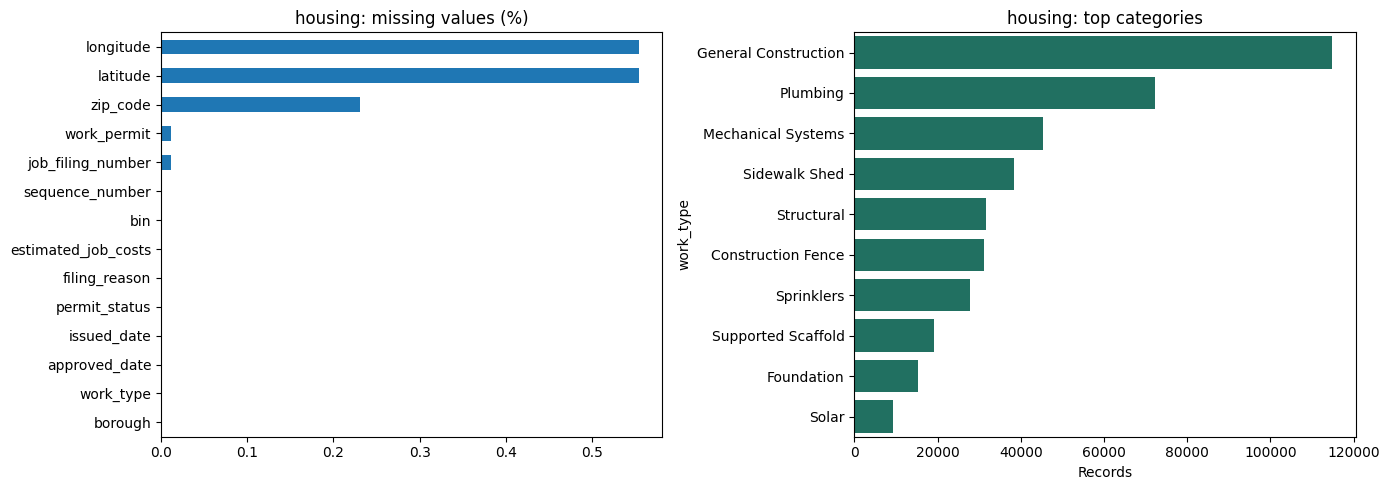

Invalid dates: 0 date range: 2022-01-01 00:00:00 2024-12-31 05:00:00
transport (262875, 12) exact duplicates: 0
                                dtype  missing_n  missing_pct  unique_n
busbreakdown_id                string          0     0.000000    262875
occurred_on                    string          0     0.000000    111390
created_on                     string          0     0.000000    133449
last_updated_on                string          0     0.000000     23008
boro                           string          9     0.003424        12
reason                         string          0     0.000000        10
run_type                       string          7     0.002663         8
how_long_delayed               string      15053     5.726296         5
number_of_students_on_the_bus  string          0     0.000000       160
breakdown_or_running_late      string          0     0.000000         2
school_year                    string          0     0.000000         4
route_number            

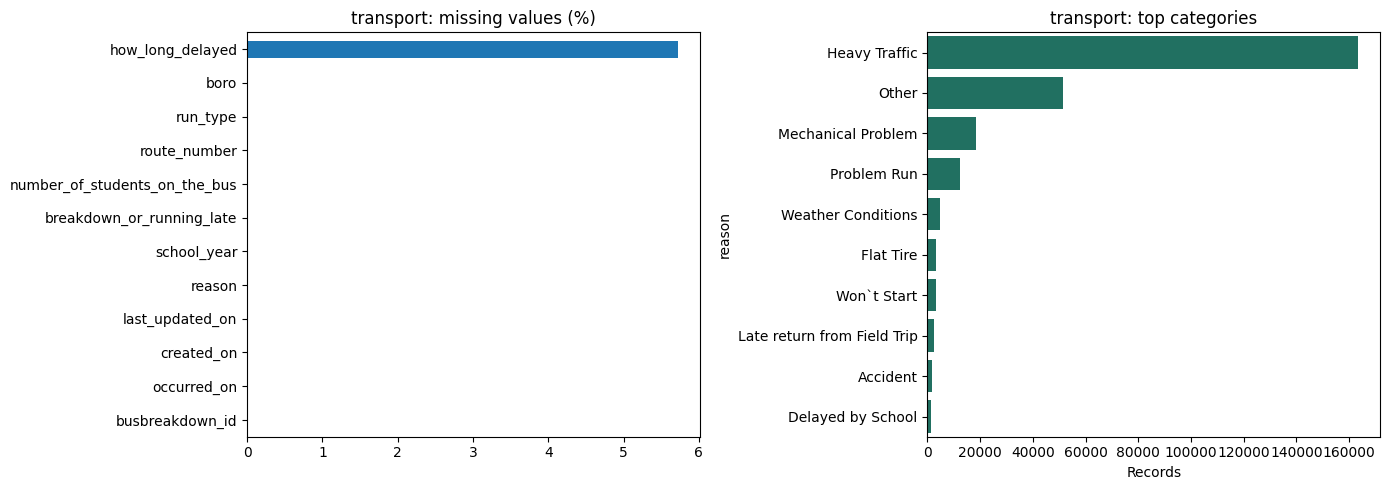

Invalid dates: 0 date range: 2022-01-03 05:25:00 2024-12-31 14:57:00


In [49]:
display(raw['housing'].head()); display(raw['transport'].head())
profiles={name:inspect(name,df) for name,df in raw.items()}

Decisions and ownership
Member 1 handles housing; Member 2 handles bus records. Drop unusable join keys and missing IDs; never impute borough/month. Retain UNKNOWN categories. Numeric outcomes remain null when invalid. ZIP strings preserve leading zeros; invalid coordinates are nulled without dropping otherwise useful borough records.
Housing exact duplicates are removed first. Profiling revealed multi-work permits sharing filing/permit/sequence identifiers: therefore the composite key also includes issuance date and normalized work type. Remaining conflicting records are quarantined by exclusion and counted; the raw snapshot preserves them for review. Do not deduplicate on filing number alone.
Bus IDs retain their most recently updated version. Delay ranges use midpoint estimates, not exact observed durations. Free text/open-ended ranges remain unknown. The 240-minute and 100-student plausibility thresholds are analysis assumptions and require sensitivity checks. Large valid construction costs are flagged by IQR and retained: extreme cost alone does not establish an error. Costs are not summed across permit records.

,housing,transport
input_rows,461557.0,262875.0
exact_duplicates_removed,87.0,0.0
invalid_geography_or_date_removed,0.0,21013.0
missing_identifier_removed,60.0,0.0
placeholder_identifiers_removed,1.0,NaN
conflicting_key_rows_quarantined,16.0,NaN
negative_costs,0.0,NaN
cost_iqr_outliers_retained,66900.0,NaN
output_rows,461393.0,241862.0
duplicate_ids_removed,NaN,0.0


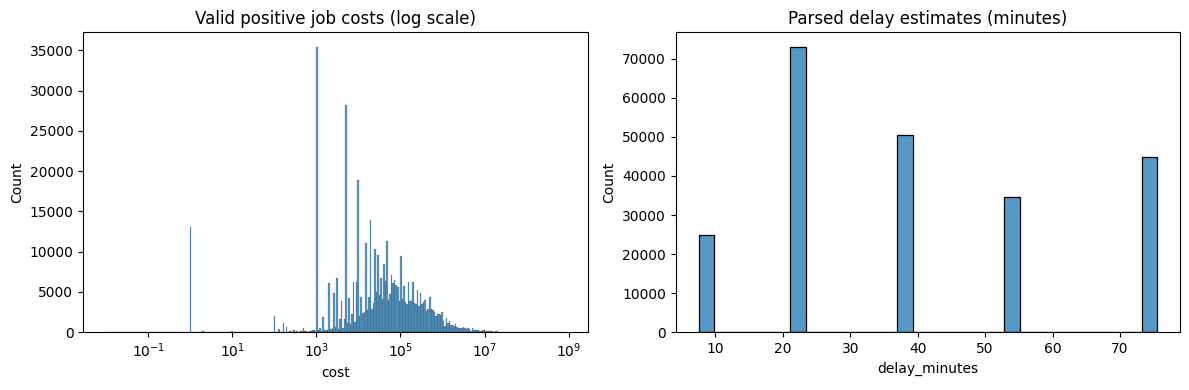

Costs (not summed across permits):
 count          461393.0
mean      277786.629129
std      3229956.591522
min                 0.0
25%              5000.0
50%             25000.0
75%            108700.0
max         800010000.0
Name: cost, dtype: Float64
Delay minutes:
 count    227934.000000
mean         39.532044
std          21.973799
min           7.500000
25%          23.000000
50%          38.000000
75%          53.000000
max          75.500000
Name: delay_minutes, dtype: float64


,job_filing_number,cost
17,M00683929-I1,520000.0
21,M08032747-I1,964858.2
24,M00826042-I1,3519892.0
28,Q00327215-I1,335475.0
34,B00589419-I1,300500.0


Delay parsing coverage: 0.942413442376231
Missing values after cleaning:


,0
job_filing_number,0
work_permit,0
sequence_number,0
borough,0
issued_date,0
approved_date,0
work_type,0
permit_status,0
zip_code,1056
bin,0


,0
busbreakdown_id,0
occurred_on,0
created_on,0
last_updated_on,0
boro,0
reason,0
run_type,7
how_long_delayed,13928
number_of_students_on_the_bus,0
breakdown_or_running_late,0


In [50]:
housing, housing_audit = clean(raw['housing'], 'housing')
transport, transport_audit = clean(raw['transport'], 'transport')
display(pd.DataFrame({'housing':housing_audit,'transport':transport_audit}))
numeric_eda(housing,transport)
display(housing.loc[housing.cost_iqr_outlier,['job_filing_number','cost']].head())
print('Delay parsing coverage:',transport.delay_minutes.notna().mean())
print('Missing values after cleaning:')
display(housing.isna().sum());display(transport.isna().sum())

C. Integration and post-cleaning
Member 3 owns aggregation; Member 4 audits the result. Filter categories within each source first, aggregate to borough-month, then outer join with one-to-one validation. Category absent within an observed source-month is a structural zero in the extract. Entire missing source-month remains unknown. Weighted means use valid-observation counts. Paired charts exclude unmatched rows, while this audit retains them.

In [51]:
ha,ta=aggregate(housing,transport)
panel=integrate(ha,ta)
display(panel.head());display(panel.coverage.value_counts())
assert not panel.duplicated(['borough','month']).any()
assert panel.permits.sum()==len(housing)
assert panel.incidents.sum()==len(transport)
assert (panel.delay_n<=panel.incidents).all()
assert pd.api.types.is_datetime64_any_dtype(panel.month)
assert pd.api.types.is_integer_dtype(panel.year)
print('Observed month range:',panel.month.min(),panel.month.max())
print('Unmatched rows:');display(panel[panel.coverage.astype(str)!='both'])
for name,frame in [('housing_monthly',ha),('transport_monthly',ta),('integrated',panel)]:
    frame.to_csv(ROOT/f'data/processed/{name}.csv',index=False)

,borough,month,coverage,permits,incidents,delay_sum,delay_n,student_sum,student_n,mean_delay,mean_students,delay_coverage,year
0,BRONX,2022-01-01,both,782,1865,51139.5,1799,4032,1863,28.426626,2.164251,0.964611,2022
1,BRONX,2022-02-01,both,836,1745,41785.5,1650,5684,1745,25.324545,3.257307,0.945559,2022
2,BRONX,2022-03-01,both,1241,2184,47817.5,2048,6965,2182,23.348389,3.192026,0.937729,2022
3,BRONX,2022-04-01,both,1180,1434,35851.5,1357,4031,1433,26.419676,2.81298,0.946304,2022
4,BRONX,2022-05-01,both,1415,1962,48680.0,1842,4990,1962,26.427796,2.543323,0.938838,2022


,count
coverage,
both,180
left_only,0
right_only,0


Observed month range: 2022-01-01 00:00:00 2024-12-01 00:00:00
Unmatched rows:


,borough,month,coverage,permits,incidents,delay_sum,delay_n,student_sum,student_n,mean_delay,mean_students,delay_coverage,year


Sensitivity and interpretation checks
Compare record-based counts with a narrower unique-permit-per-month definition. Compare all parseable delay estimates with a stricter ≤120-minute subset. Different correlations or delay averages indicate dependence on operational definitions; neither specification establishes causation.

In [52]:
unique=housing.drop_duplicates(['borough','month','work_permit'])
hu,_=aggregate(unique,transport)
p_unique=integrate(hu,ta)
print('Record-count correlation:',panel.permits.rank().corr(panel.incidents.rank()))
print('Unique-permit correlation:',p_unique.permits.rank().corr(p_unique.incidents.rank()))
print('Delay mean, parsed <=240:',transport.delay_minutes.mean())
print('Delay mean, parsed <=120:',transport.loc[transport.delay_minutes<=120,'delay_minutes'].mean())
print('Valid cost median, all:',housing.cost.median())
print('Valid cost median, excluding IQR flags:',housing.loc[~housing.cost_iqr_outlier,'cost'].median())

Record-count correlation: 0.25399408930857525
Unique-permit correlation: 0.26041741150574776
Delay mean, parsed <=240: 39.53204436371932
Delay mean, parsed <=120: 39.53204436371932
Valid cost median, all: 25000.0
Valid cost median, excluding IQR flags: 15240.0


D. Exactly eight research questions and visualizations
All charts use matched source-months. Change the selections below to reproduce dashboard filters. Each question has one separately runnable visualization cell. Full reusable Plotly code is in charts.py; figures() returns exactly eight charts.

In [53]:
selected=integrate(ha,ta,hcategory='ALL',tcategory='ALL')
selected=selected[selected.year.isin([2022,2023,2024])]
research_figures=figures(selected)

Q1 — Member 1
Do borough-months with more permit activity also report more school-bus incidents?
Scatter: counts, coloured by borough; exposes scale confounding.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom.

In [54]:
research_figures[0].show()

Q2 — Member 1
Do permit and incident trends move together within each borough relative to its first selected month?
Indexed time series: baseline 100, one panel per borough.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom.

In [55]:
research_figures[1].show()

Q3 — Member 2
Which seasons show unusually high incident reporting relative to development activity?
Heatmap: incident seasonal index minus permit seasonal index.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom.

In [56]:
research_figures[2].show()

Q4 — Member 2
Are year-over-year changes in permits associated with changes in incident reports?
Scatter: same-month annual percentage changes, avoiding adjacent-season comparisons.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom.

In [57]:
research_figures[3].show()

Q5 — Member 3
Is permit activity associated with incident reporting one to three months later?
Heatmap: within-borough Spearman correlations at calendar-aligned lags, including lag zero.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom.

In [58]:
research_figures[4].show()

Q6 — Member 3
Are reported delays longer in high-permit months than low-permit months within a borough?
Box plot of monthly mean delay, split at each borough’s median permit count.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom.

In [59]:
research_figures[5].show()

Q7 — Member 4
Which boroughs account for a larger share of reported incidents than of permit activity?
Grouped share bars: descriptive concentration, not an exposure-adjusted risk.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom.

In [60]:
research_figures[6].show()

Q8 — Member 4
Does the relationship persist after removing borough and shared calendar-month effects?
Residual scatter: additive borough and date fixed effects for both count variables.
Interpret the magnitude, seasonal/size confounding and relevant denominator. Write a brief conclusion supported by this chart, and avoid causal language. Q5 requires at least 12 calendar-aligned pairs; Q6 requires 10 usable delays per month; Q8 requires at least five residual degrees of freedom

In [61]:
research_figures[7].show()

E. Findings, limitations and NYC impact
The following story is computed from the selected data. The findings below are computed from this runtime’s downloaded snapshot. Use the results to nominate periods for investigation by DOB and DOE, not to infer individual household experiences or rank route performance.

In [62]:
print(story(selected))

For the applied filters, 180 matched borough-months contain 461,393 permit records and 241,862 reported school-bus incidents. The pooled Spearman correlation is 0.25. This is a descriptive association, not evidence that construction causes delays. Borough size, school schedules, reporting practices and traffic exposure can explain co-movement. Permits include non-residential work and do not measure completed homes. Incident reports exclude on-time journeys; rates of failure cannot be calculated. Use these patterns to nominate boroughs and periods for joint DOB/DOE review and route-level follow-up, not to rank safety or assign blame.


5. Validate and record findings
These tests check cleaning and integration rules. Review every finding and replace team placeholders before submission.

In [63]:
import subprocess
subprocess.run([sys.executable, '-m', 'pytest', '-q'], cwd=PROJECT, check=True)
subprocess.run([sys.executable, 'report_results.py'], cwd=PROJECT, check=True)
display(Markdown((PROJECT / 'reports/FINDINGS.md').read_text()))

# Snapshot findings

ALL categories, all five boroughs, 2022–2024. Descriptive only; no causal/significance claims. Recompute with `python report_results.py`.

**Q1.** Pooled Spearman correlation: 0.254, across 180 borough-months. Borough size may explain co-movement.

**Q2.** Final-month indices (January 2022=100): BRONX: permits 163.4, incidents 101.0; BROOKLYN: permits 141.7, incidents 152.4; MANHATTAN: permits 109.7, incidents 68.2; QUEENS: permits 139.4, incidents 125.4; STATEN ISLAND: permits 171.8, incidents 88.8. Baseline-dependent endpoint comparison.

**Q3.** Largest seasonal incident-minus-permit index gap: STATEN ISLAND, month 10, 149.4 points. School schedules are a plausible explanation.

**Q4.** Spearman correlation of annual percentage changes: 0.068 (120 pairs). Reporting changes remain a limitation.

**Q5.** One-month-lag Spearman: BRONX: -0.156 (n=35); BROOKLYN: -0.245 (n=35); MANHATTAN: -0.318 (n=35); QUEENS: -0.330 (n=35); STATEN ISLAND: -0.118 (n=35). Chart includes 0–3 months; none is a causal effect or forecast.

**Q6.** Median of monthly mean delays (high/low permit months, minutes): BRONX: 28.1/28.5; BROOKLYN: 42.7/37.6; MANHATTAN: 41.7/39.8; QUEENS: 50.9/45.7; STATEN ISLAND: 38.6/37.0. These are monthly vendor-estimate summaries, not measured student journeys.

**Q7.** Largest share gap: BRONX, 15.2 percentage points (24.8% incidents, 9.6% permits). Not an exposure-adjusted failure rate.

**Q8.** Pearson correlation of residual counts after borough/calendar-month effects: 0.035, residual df=140. This is a different statistic from pooled Spearman, not proof of causation.

**NYC impact:** nominate boroughs/periods for joint DOB–DOE review, followed by route-level investigation before decisions. Permit-work records include renewals/non-residential work. Incidents exclude on-time journeys. Missing/out-of-city records, calendar seasonality and reporting changes limit generalization.

6. Interactive Dash dashboard
Run after preparing the data. Select borough/year/work type/incident reason, or search Brooklyn 2022, then click Generate Report. The dashboard shows all eight charts and a computed story.

In [64]:
import importlib
import app as dashboard
importlib.reload(dashboard)  # Reload aggregates after rerunning analysis.
from dash import jupyter_dash
jupyter_dash.infer_jupyter_proxy_config()
dashboard.app.run(jupyter_mode='inline', jupyter_height=950,
                  host='0.0.0.0', port=8050, debug=False)

<IPython.core.display.Javascript object>